# Visualització dels descriptors d’imatge

Notebook de suport per preparar una presentació PowerPoint sobre els descriptors del projecte de recuperació d’imatges. Les imatges es carreguen amb la mateixa funció `load_images()` i les mateixes carpetes que `test_desc.py`.

**Objectiu:** explicar visualment què captura cada descriptor, com es calcula, quina informació conserva i quina distància es recomana per comparar-lo.

> Aquest notebook crea imatges sintètiques d’exemple, de manera que es pot executar sense disposar de la BBDD real. Les visualitzacions són esquemàtiques i serveixen per explicar el mètode, no per afirmar quin descriptor obté millors resultats al conjunt real.

Descriptors inclosos segons `utils.py`:
- DCT per blocs
- Histograma de coeficients DCT
- Piràmide espacial DCT
- DWT / wavelets per blocs (estadístiques)
- Histogrames de coeficients DWT
- LBP per blocs


Projecte: C:\Users\Lenovo\Albert\CVC\mcv\c1
BBDD: 287 imatges
Queries (qsd1_w3): 30 imatges
IDs disponibles: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29


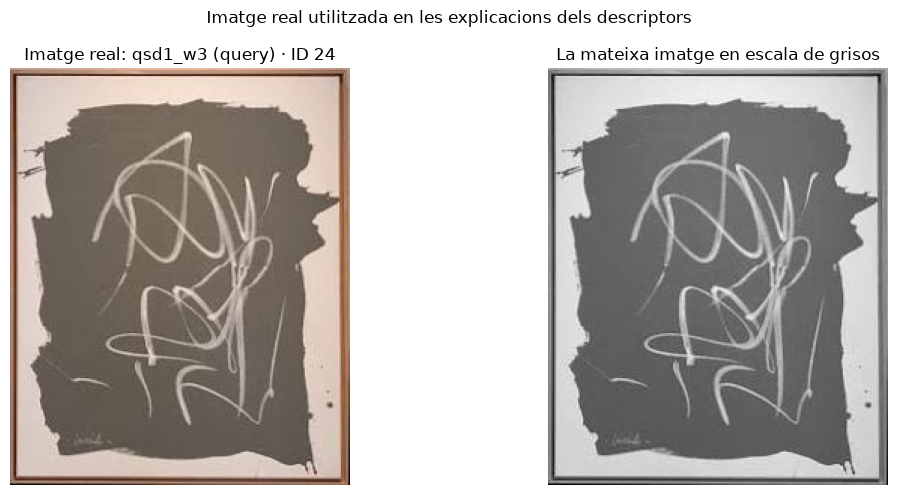

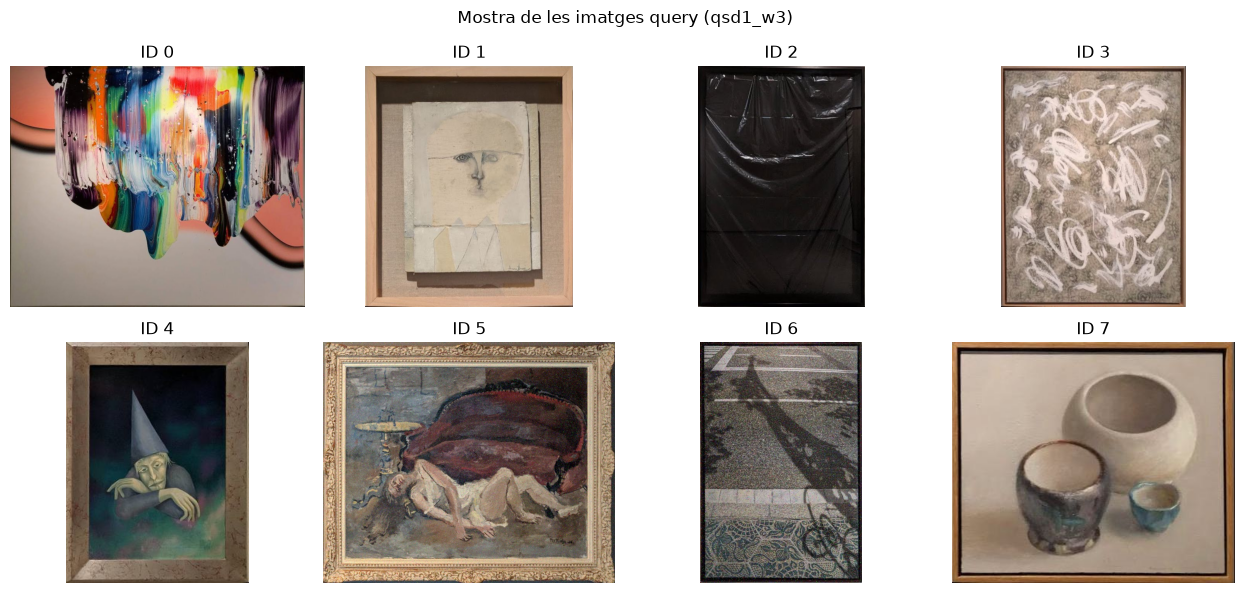

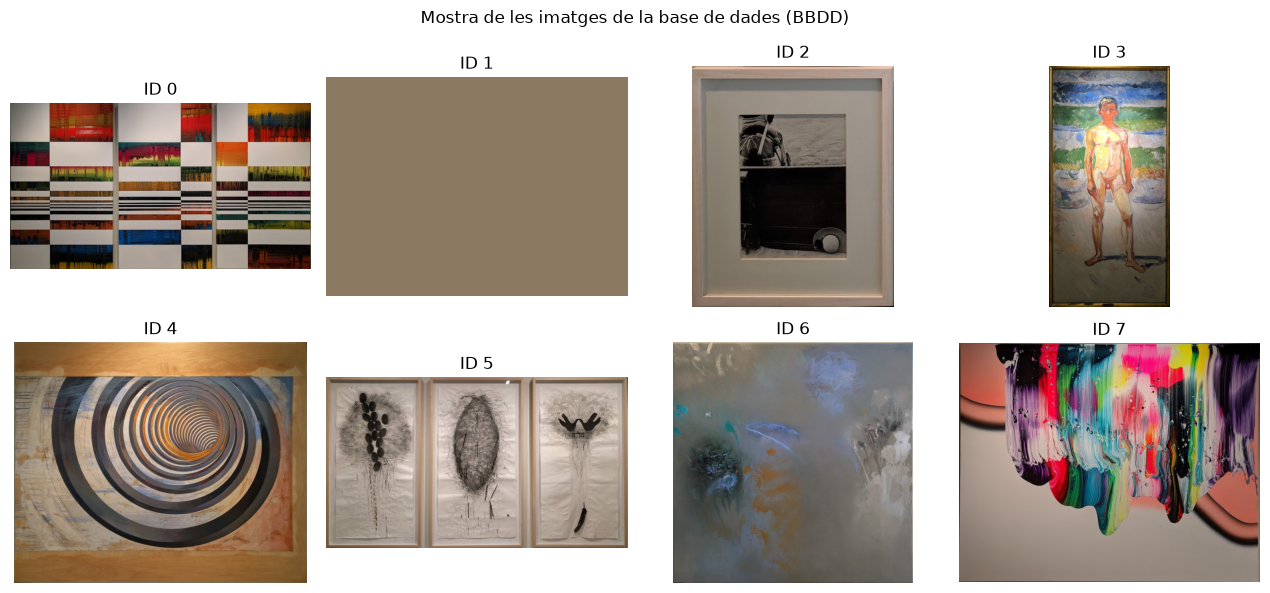

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import pywt
from skimage.feature import local_binary_pattern
from math import ceil
from pathlib import Path
import sys

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["image.cmap"] = "gray"

# ------------------------------------------------------------------
# Càrrega de dades: mateixa funció i noms de carpetes que test_desc.py
# test_desc.py fa: DATA_DIR = Path(__file__).resolve().parent.parent / "data"
# En un notebook, __file__ no existeix; per això busquem la carpeta data
# al directori actual i als seus directoris pares.
# ------------------------------------------------------------------
possible_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = None
for root in possible_roots:
    if (root / "data" / "BBDD").is_dir() and (root / "data" / "qsd1_w3").is_dir():
        PROJECT_ROOT = root
        break
    # També permet executar el notebook des d'una carpeta notebooks/ o similar.
    if (root.parent / "data" / "BBDD").is_dir() and (root.parent / "data" / "qsd1_w3").is_dir():
        PROJECT_ROOT = root.parent
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No trobo les carpetes data/BBDD i data/qsd1_w3. "
        "Desa/executa aquest notebook dins del projecte, o modifica PROJECT_ROOT manualment."
    )

DATA_DIR = PROJECT_ROOT / "data"
BBDD_DIR = DATA_DIR / "BBDD"
QUERY_DIR = DATA_DIR / "qsd1_w3"
sys.path.insert(0, str(PROJECT_ROOT))

from utils import *  # reutilitza load_images(), preprocess() i descriptors del projecte

# Igual que test_desc.py: carrega IDs i imatges JPG ordenades per nom.
db_ids, db_images = load_images(BBDD_DIR)
query_ids, query_images = load_images(QUERY_DIR)

print(f"Projecte: {PROJECT_ROOT}")
print(f"BBDD: {len(db_images)} imatges")
print(f"Queries (qsd1_w3): {len(query_images)} imatges")
if not db_images and not query_images:
    raise RuntimeError("No s'han carregat imatges. Comprova les rutes i que hi hagi fitxers .jpg.")

# Tria la col·lecció i l'ID de la imatge que vols visualitzar.
# Introdueix "q" per a qsd1_w3 (queries) o "b" per a BBDD.
if query_images and db_images:
    source_choice = input("Col·lecció: [q] qsd1_w3 / [b] BBDD: ").strip().lower()
    if source_choice not in ("q", "b"):
        print("Opció no vàlida; es farà servir qsd1_w3.")
        source_choice = "q"
elif query_images:
    source_choice = "q"
else:
    source_choice = "b"

if source_choice == "q":
    available_ids, available_images = query_ids, query_images
    example_source = "qsd1_w3 (query)"
else:
    available_ids, available_images = db_ids, db_images
    example_source = "BBDD"

if not available_images:
    raise RuntimeError(f"No hi ha imatges disponibles a {example_source}.")

print("IDs disponibles:", ", ".join(map(str, available_ids)))
chosen_id = input("Escriu l'ID de la imatge que vols mostrar: ").strip()

# Compara com a text per permetre IDs numèrics o alfanumèrics.
id_to_index = {str(image_id): i for i, image_id in enumerate(available_ids)}
if chosen_id not in id_to_index:
    print(f"ID {chosen_id!r} no trobat; es mostrarà la primera imatge (ID {available_ids[0]}).")
    selected_index = 0
else:
    selected_index = id_to_index[chosen_id]

img = available_images[selected_index]
example_id = available_ids[selected_index]

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def show_image(ax, image, title):
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
show_image(ax[0], rgb, f"Imatge real: {example_source} · ID {example_id}")
show_image(ax[1], gray, "La mateixa imatge en escala de grisos")
plt.suptitle("Imatge real utilitzada en les explicacions dels descriptors")
plt.tight_layout()
plt.show()

# Mostra visual ràpida de diverses imatges del dataset per contextualitzar el projecte.
def show_montage(images, ids, title, n=8):
    if not images:
        print(f"No hi ha imatges per mostrar a {title}.")
        return
    count = min(n, len(images))
    cols = min(4, count)
    rows = ceil(count / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.0 * rows))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        if i < count:
            show_image(ax, cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB), f"ID {ids[i]}")
        else:
            ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_montage(query_images, query_ids, "Mostra de les imatges query (qsd1_w3)")
show_montage(db_images, db_ids, "Mostra de les imatges de la base de dades (BBDD)")


## Com es carreguen les imatges (igual que al test)

El notebook reutilitza `load_images()` de `utils.py`, tal com fa `test_desc.py`. Aquesta funció llegeix els fitxers `*.jpg` ordenats pel nom, obre cada imatge amb OpenCV en format **BGR** i extreu l’ID del final del nom del fitxer. Es carreguen dues col·leccions: `data/BBDD` (imatges candidates) i `data/qsd1_w3` (consultes).

Per a les visualitzacions didàctiques s’agafa la primera query real disponible; si la carpeta de consultes és buida, s’utilitza la primera imatge de `BBDD`. Les visualitzacions en gris es fan només per explicar les transformacions; el pipeline real del test pot treballar amb canals de color segons `PARAMS`.


**Selecció d'imatge:** en executar la primera cel·la de codi, tria la col·lecció (`q` per `qsd1_w3` o `b` per `BBDD`) i escriu l'ID desitjat. La imatge seleccionada s'utilitza a les visualitzacions següents. Si canvies l'ID, torna a executar les cel·les de visualització dels descriptors per actualitzar-ne els gràfics.


## 1. DCT per blocs (`dct_block_descriptor`)

**Idea per explicar a la diapositiva:** divideix cada canal en una graella de blocs, calcula la Transformada Discreta del Cosinus (DCT) i guarda els mòduls dels primers coeficients en ordre zig-zag. Si `skip_dc=True`, s'omet el coeficient DC, associat al nivell mitjà del bloc.

- **Què captura?** freqüències locals: canvis suaus i detalls/vores dins de cada bloc.
- **Espai:** conserva on es troba cada bloc; els vectors es concatenen.
- **Paràmetres del codi:** `n_blocks`, `n_coef`, `skip_dc`, `normalize`.
- **Distància recomanada al codi:** euclidiana.


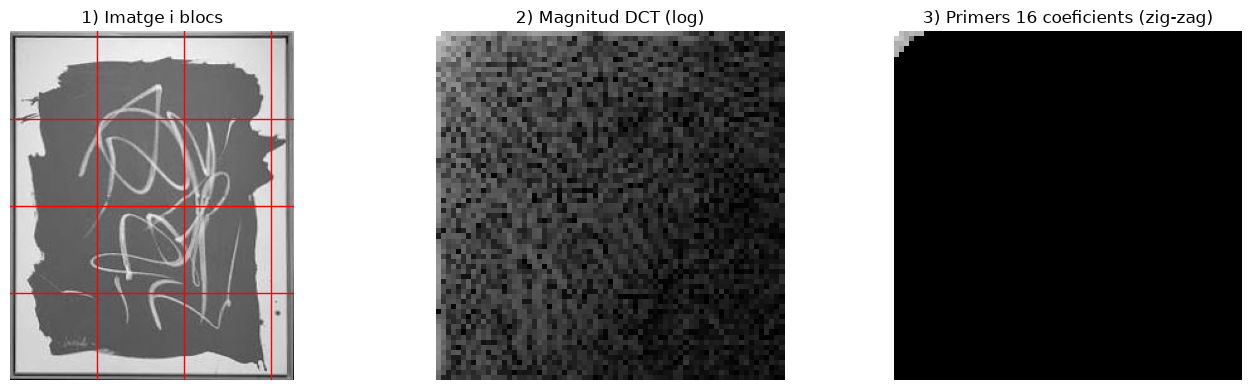

In [23]:
def zigzag_indices(n):
    return sorted(((i, j) for i in range(n) for j in range(n)),
                  key=lambda p: (p[0] + p[1],
                                 p[0] if (p[0] + p[1]) % 2 else p[1]))

def dct_block_visual(gray, n_blocks=4, n_coef=16):
    h, w = gray.shape
    b = h // n_blocks
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    show_image(ax[0], gray, "1) Imatge i blocs")
    for k in range(1, n_blocks):
        ax[0].axhline(k*b, color="red", lw=1)
        ax[0].axvline(k*b, color="red", lw=1)
    block = gray[:b, :b].astype(np.float32)
    d = cv2.dct(block)
    show_image(ax[1], np.log1p(np.abs(d)), "2) Magnitud DCT (log)")
    idx = zigzag_indices(b)[:n_coef]
    mask = np.zeros_like(d)
    for y, x in idx:
        mask[y, x] = abs(d[y, x])
    show_image(ax[2], np.log1p(mask), f"3) Primers {n_coef} coeficients (zig-zag)")
    plt.tight_layout()
    plt.show()

dct_block_visual(gray)


**Lectura visual:** les freqüències baixes acostumen a concentrar-se a la cantonada superior esquerra de la DCT. L'ordre zig-zag visita primer aquestes freqüències i després les més altes. La visualització mostra un bloc; el descriptor real concatena els coeficients seleccionats de tots els blocs i canals.


## 2. Histograma DCT (`dct_histogram_descriptor`)

En lloc de conservar cada coeficient en una posició fixa, aquest descriptor agrupa els blocs en regions espacials i calcula **histogrames** dels valors `log(1 + |coeficient|)` per a cada freqüència seleccionada.

- **Què captura?** distribució de l'energia/freqüències locals dins de cada regió.
- **Avantatge:** resumeix molts blocs amb estadístiques de distribució.
- **Limitació:** no conserva la posició exacta de cada bloc dins de la regió.
- **Distàncies recomanades al codi:** chi-quadrat o Hellinger.


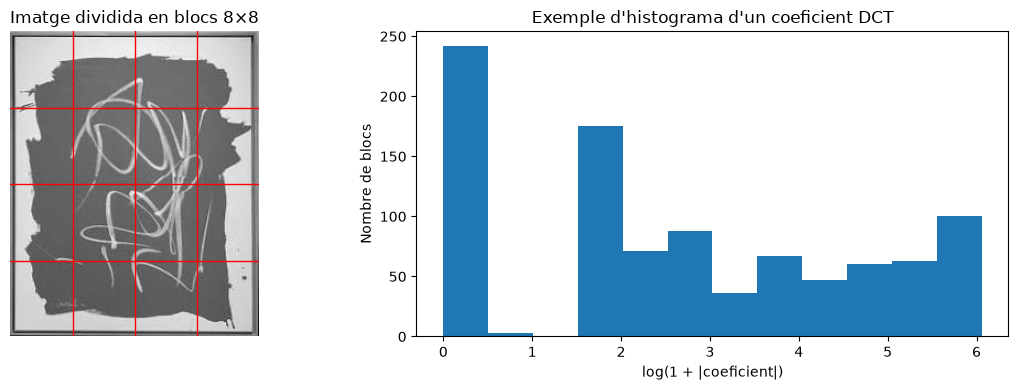

In [24]:
def dct_histogram_visual(gray, block_size=8, n_coef=8, n_regions=4, n_bins=12):
    h, w = gray.shape
    values = []
    for y in range(0, h-block_size+1, block_size):
        for x in range(0, w-block_size+1, block_size):
            d = cv2.dct(gray[y:y+block_size, x:x+block_size].astype(np.float32))
            idx = zigzag_indices(block_size)[1:n_coef+1]
            values.append([np.log1p(abs(d[i,j])) for i,j in idx])
    values = np.array(values)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    show_image(ax[0], gray, "Imatge dividida en blocs 8×8")
    for k in range(1, n_regions):
        ax[0].axhline(k*h/n_regions, color="red", lw=1)
        ax[0].axvline(k*w/n_regions, color="red", lw=1)
    ax[1].hist(values[:, 0], bins=n_bins)
    ax[1].set_title("Exemple d'histograma d'un coeficient DCT")
    ax[1].set_xlabel("log(1 + |coeficient|)")
    ax[1].set_ylabel("Nombre de blocs")
    plt.tight_layout()
    plt.show()

dct_histogram_visual(gray)


## 3. Piràmide espacial DCT (`dct_pyramid_descriptor`)

Calcula descriptors DCT per a diverses particions de la imatge —per defecte, nivells `1×1`, `3×3` i `4×4`— i concatena els vectors, opcionalment ponderats.

- **Nivell gruixut (1×1):** resum global.
- **Nivells fins:** aporten més informació sobre la distribució espacial.
- **Què captura?** una combinació de contingut global i estructura local.
- **Distància recomanada al codi:** euclidiana.


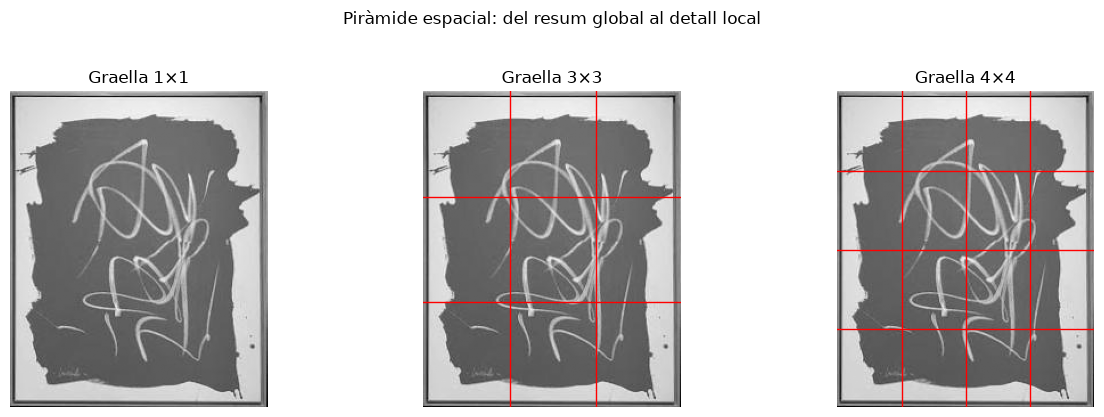

In [25]:
def draw_grid(ax, image, n, color="red"):
    show_image(ax, image, f"Graella {n}×{n}")
    h, w = image.shape[:2]
    for k in range(1, n):
        ax.axhline(k*h/n, color=color, lw=1)
        ax.axvline(k*w/n, color=color, lw=1)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
draw_grid(ax[0], gray, 1)
draw_grid(ax[1], gray, 3)
draw_grid(ax[2], gray, 4)
plt.suptitle("Piràmide espacial: del resum global al detall local", y=1.03)
plt.tight_layout()
plt.show()


## 4. Estadístiques wavelet / DWT (`dwt_block_descriptor`)

La transformada wavelet descompon cada bloc en subbandes de detall horitzontal, vertical i diagonal a diversos nivells. El descriptor guarda, per subbanda, la mitjana del valor absolut i la desviació estàndard dels coeficients.

- **Què captura?** intensitat i variabilitat dels detalls en diferents escales i orientacions.
- **Interpretació:** les subbandes representen tipus de canvi diferents; els nivells més profunds corresponen a escales més grans.
- **Paràmetres:** `wavelet` (p. ex. Haar), `levels`, `n_blocks`.
- **Distància recomanada al codi:** euclidiana.


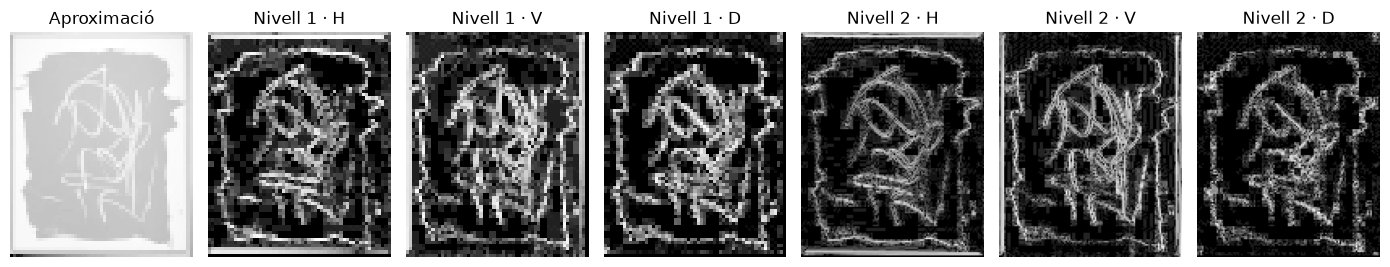

In [26]:
def wavelet_visual(gray, wavelet="haar", level=2):
    coeffs = pywt.wavedec2(gray.astype(np.float32), wavelet, level=level)
    # coeffs: approximation, then (horizontal, vertical, diagonal) details per level
    approx = coeffs[0]
    details = coeffs[1:]
    fig, axes = plt.subplots(1, 1 + 3*len(details), figsize=(14, 3))
    show_image(axes[0], np.log1p(np.abs(approx)), "Aproximació")
    j = 1
    for li, (cH, cV, cD) in enumerate(details, start=1):
        for band, name in [(cH, "H"), (cV, "V"), (cD, "D")]:
            show_image(axes[j], np.log1p(np.abs(band)), f"Nivell {li} · {name}")
            j += 1
    plt.tight_layout()
    plt.show()

wavelet_visual(gray)


## 5. Histogrames wavelet (`dwt_histogram_descriptor`)

També fa una descomposició DWT, però en lloc de resumir cada subbanda amb mitjana i desviació estàndard, calcula histogrames de `log(1 + |coeficient|)` per subbanda i bloc.

- **Què captura?** distribucions dels detalls per escala, orientació i bloc.
- **Diferència respecte a DWT estadístic:** histogrames més detallats, a canvi d'un vector més gran.
- **Distàncies recomanades al codi:** chi-quadrat o Hellinger.


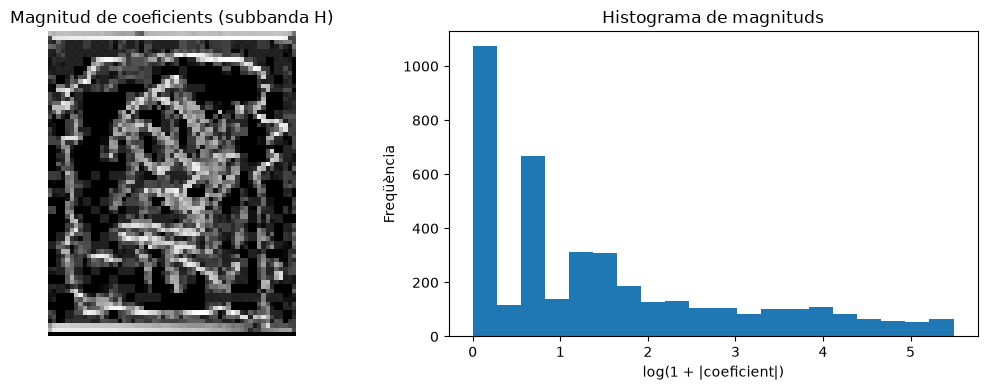

In [27]:
# Exemple de distribució dels coeficients d'una subbanda wavelet
coeffs = pywt.wavedec2(gray.astype(np.float32), "haar", level=2)
cH, cV, cD = coeffs[1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
show_image(ax[0], np.log1p(np.abs(cH)), "Magnitud de coeficients (subbanda H)")
ax[1].hist(np.log1p(np.abs(cH)).ravel(), bins=20)
ax[1].set_title("Histograma de magnituds")
ax[1].set_xlabel("log(1 + |coeficient|)")
ax[1].set_ylabel("Freqüència")
plt.tight_layout()
plt.show()


## 6. LBP per blocs (`lbp_block_descriptor`)

Local Binary Patterns compara cada píxel amb els seus veïns i codifica el patró local de més gran/menor intensitat. Després calcula un histograma de codis LBP per a cada bloc.

- **Què captura?** microtextures i patrons locals, més que no pas el color o la forma global.
- **Paràmetres:** nombre de veïns `P`, radi `R`, mètode (`uniform` o `default`) i nombre de blocs.
- **Distàncies recomanades al codi:** chi-quadrat o Hellinger.


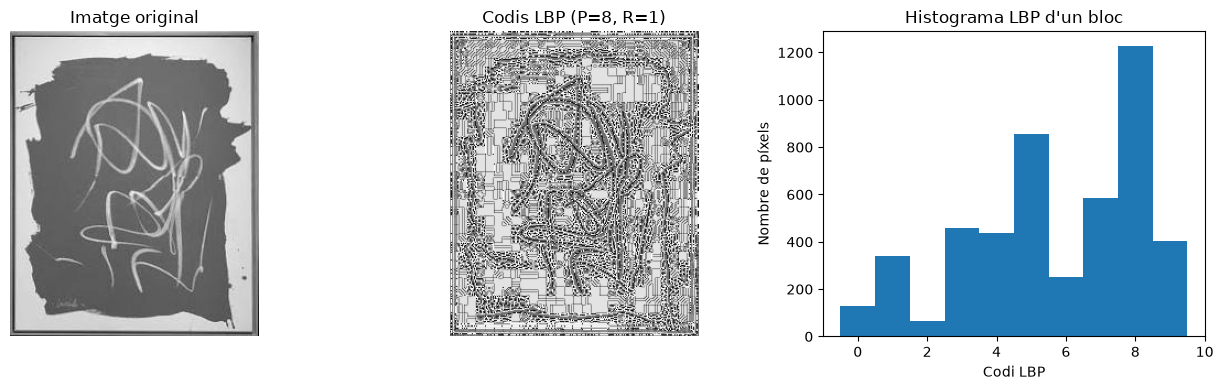

In [28]:
def lbp_visual(gray, P=8, R=1, n_blocks=4):
    lbp = local_binary_pattern(gray, P, R, method="uniform")
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    show_image(ax[0], gray, "Imatge original")
    show_image(ax[1], lbp, f"Codis LBP (P={P}, R={R})")
    b = gray.shape[0] // n_blocks
    patch = lbp[:b, :b]
    n_bins = P + 2
    ax[2].hist(patch.ravel(), bins=np.arange(n_bins+1)-0.5)
    ax[2].set_title("Histograma LBP d'un bloc")
    ax[2].set_xlabel("Codi LBP")
    ax[2].set_ylabel("Nombre de píxels")
    plt.tight_layout()
    plt.show()

lbp_visual(gray)


## Comparació resum per a les diapositives

| Descriptor | Representació | Informació principal | Distàncies recomanades al codi |
|---|---|---|---|
| DCT per blocs | Coeficients seleccionats en ordre zig-zag | Freqüències locals amb posició espacial | Euclidiana |
| Histograma DCT | Histogrames per regió i coeficient | Distribució de freqüències | Chi-quadrat, Hellinger |
| Piràmide DCT | DCT a diverses escales espacials | Informació global + local | Euclidiana |
| DWT estadístic | Mitjana absoluta i desviació estàndard de subbandes | Detall per escala i orientació | Euclidiana |
| Histograma DWT | Histogrames per subbanda i bloc | Distribució de detalls wavelet | Chi-quadrat, Hellinger |
| LBP per blocs | Histogrames de patrons locals | Microtextures | Chi-quadrat, Hellinger |

**Important:** les distàncies recomanades s'han extret dels docstrings de `utils.py`. El millor descriptor per al projecte s'ha de determinar amb l'avaluació real (per exemple, mAP@1 i mAP@5), no només amb aquestes figures.


## Proposta d'estructura del PowerPoint

1. **Objectiu:** convertir cada imatge en un vector numèric comparable.
2. **DCT per blocs:** graella → transformada → selecció zig-zag.
3. **Histograma DCT:** comparar distribucions, no coeficients exactes.
4. **Piràmide DCT:** compromís entre context global i detall local.
5. **Wavelets:** separar detalls per escala i orientació.
6. **LBP:** representar patrons de textura local.
7. **Taula comparativa:** informació capturada, avantatges i limitacions.
8. **Resultats experimentals:** afegir mAP@1/mAP@5 calculats sobre el conjunt de dades real.

Per a cada descriptor, una diapositiva pot seguir el patró: **intuïció → visualització → vector que es genera → distància → limitació**.
